In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))
        

/kaggle/input/datasets/ulrikthygepedersen/online-retail-dataset/online_retail.csv


In [2]:
import pandas as pd
import os

path = None
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith((".csv", ".xlsx")):
            path = os.path.join(root, f)

print("File:", path)

if path.endswith(".csv"):
    df = pd.read_csv(path, encoding="ISO-8859-1")
else:
    df = pd.read_excel(path)

print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df.describe())


File: /kaggle/input/datasets/ulrikthygepedersen/online-retail-dataset/online_retail.csv
(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicates: 5268
            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000

In [3]:
# Column names standard karo
df = df.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
raw_rows = len(df)
report = {}

# 1. Duplicates
report["Duplicate rows"] = int(df.duplicated().sum())
df = df.drop_duplicates()

# 2. Missing values
report["Missing CustomerID"] = int(df["CustomerID"].isnull().sum())
report["Missing Description"] = int(df["Description"].isnull().sum())
df["HasCustomerID"] = df["CustomerID"].notnull()
df = df.dropna(subset=["Description"])

# 3. Date format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
report["Invalid dates"] = int(df["InvoiceDate"].isnull().sum())
df = df.dropna(subset=["InvoiceDate"])

# 4. Cancelled orders
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["IsCancelled"] = df["InvoiceNo"].str.startswith("C")
report["Cancelled orders"] = int(df["IsCancelled"].sum())

# 5. Galat values
bad_price = df["UnitPrice"] <= 0
bad_qty = (df["Quantity"] <= 0) & ~df["IsCancelled"]
report["Zero/negative price"] = int(bad_price.sum())
report["Negative qty (not cancelled)"] = int(bad_qty.sum())
df = df[~bad_price & ~bad_qty]

# 6. Text cleaning
df["Description"] = df["Description"].str.strip().str.upper()

# 7. Outliers (IQR method, sirf flag karenge, delete nahi)
q = df[~df["IsCancelled"]]["Quantity"]
q1, q3 = q.quantile(0.25), q.quantile(0.75)
iqr = q3 - q1
df["QtyOutlier"] = (df["Quantity"] > q3 + 1.5 * iqr) & ~df["IsCancelled"]
report["Quantity outliers flagged"] = int(df["QtyOutlier"].sum())

# Quality report
print("Rows before:", raw_rows)
print("Rows after :", len(df))
print()
for k, v in report.items():
    print(f"{k}: {v}")

Rows before: 541909
Rows after : 534129

Duplicate rows: 5268
Missing CustomerID: 135037
Missing Description: 1454
Invalid dates: 0
Cancelled orders: 9251
Zero/negative price: 1058
Negative qty (not cancelled): 474
Quantity outliers flagged: 27111


                          Issue   Count
0                Duplicate rows    5268
1            Missing CustomerID  135037
2           Missing Description    1454
3                 Invalid dates       0
4              Cancelled orders    9251
5           Zero/negative price    1058
6  Negative qty (not cancelled)     474
7     Quantity outliers flagged   27111
8          Rows before cleaning  541909
9           Rows after cleaning  534129


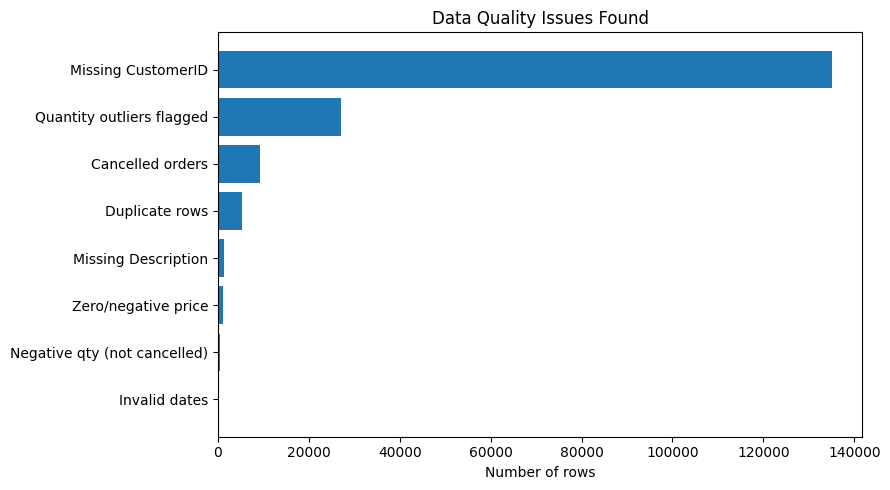

In [4]:
import matplotlib.pyplot as plt

# Cleaned data save karo
df.to_csv("cleaned_online_retail.csv", index=False)

# Quality report ko table mein badlo aur save karo
report_df = pd.DataFrame(list(report.items()), columns=["Issue", "Count"])
report_df.loc[len(report_df)] = ["Rows before cleaning", raw_rows]
report_df.loc[len(report_df)] = ["Rows after cleaning", len(df)]
report_df.to_csv("data_quality_report.csv", index=False)
print(report_df)

# Chart banao
plot_df = report_df.iloc[:len(report)].sort_values("Count")
plt.figure(figsize=(9, 5))
plt.barh(plot_df["Issue"], plot_df["Count"])
plt.title("Data Quality Issues Found")
plt.xlabel("Number of rows")
plt.tight_layout()
plt.savefig("quality_issues_chart.png", dpi=150)
plt.show()